In [8]:
import pandas as pd

df_An = pd.read_csv("Fw_radii_-_collection_from_spherical_1D/radii-systematic/collect.FyDr", sep="\\s+", skiprows=1)
df_An.tail()

,Z,N,r_C,E_B,"Epair,p",Epair_n,gap_p,gap_n,eferm_p,eferm_n
150,82,212,6.112870,-1826.70,-24.063,-318.429,1.702,6.034,-19.097,1.655
151,82,214,6.123050,-1825.31,-24.239,-322.177,1.705,6.032,-19.326,1.754
152,82,216,6.133275,-1823.88,-24.452,-326.477,1.709,6.033,-19.548,1.851
153,82,218,6.143602,-1822.49,-24.721,-331.659,1.716,6.041,-19.762,1.947
154,82,220,6.154079,-1821.25,-25.063,-338.070,1.725,6.059,-19.967,2.040


In [11]:
df_Sud = pd.read_csv("minimum_energies_FyDr_new.dat", sep="\\s+")
df_Sud.rename(columns={"Ncharge": "Z", "Nmass": "A", "energy": "E_B"}, inplace=True)
df_Sud["N"] = df_Sud["A"] - df_Sud["Z"]
df_Sud.tail()

,bet2,bet2p,bet2n,bet4,bet4p,bet4n,E_B,epairp,epairn,ferp,...,rmsc,rms,rmsp,rmsn,N_boundp,N_boundn,j,A,Z,N
624,0.285,0.293,0.279,0.028,0.031,0.026,-1907.890,-23.0,-75.4,-1.29,...,6.1384,6.1071,6.0945,6.1212,102.7970,152.4810,4.496028,260,106,154
625,0.281,0.290,0.276,0.022,0.024,0.020,-1922.617,-22.9,-79.4,-1.67,...,6.1498,6.1228,6.1063,6.1395,103.5301,154.3700,4.451453,262,106,156
626,0.273,0.281,0.268,0.006,0.007,0.005,-1924.075,-17.6,-50.0,-0.90,...,6.1406,6.1044,6.0963,6.1149,104.8595,154.9942,4.880666,264,108,156
627,0.269,0.277,0.263,-0.002,-0.001,-0.004,-1938.886,-16.9,-51.9,-1.30,...,6.1502,6.1179,6.1062,6.1307,106.2077,156.9207,4.861798,266,108,158
628,0.258,0.266,0.253,-0.009,-0.008,-0.010,-1957.804,-26.9,-83.7,-0.73,...,6.2115,6.1797,6.1681,6.1930,105.9584,158.3126,4.352023,270,110,160


In [13]:
diff = df_An.merge(df_Sud, on=["Z", "N"], suffixes=('_An', '_Sud'))
diff['r_C_diff'] = diff['r_C'] - diff['rmsc']
diff['E_B_diff'] = diff['E_B_An'] - diff['E_B_Sud']
print(diff[['Z', 'N', 'r_C_diff', 'E_B_diff']])

     Z    N  r_C_diff  E_B_diff
0   20   16  0.015049    1.5752
1   20   18 -0.012970    1.8403
2   20   20 -0.064922    0.2242
3   20   22 -0.030057    1.3434
4   20   24 -0.039080    1.1773
5   20   26 -0.014768    1.4439
6   20   28 -0.028618    1.7081
7   20   30 -0.011506    1.3241
8   20   32 -0.042937    0.3122
9   20   34 -0.060799   -1.2365
10  20   36 -0.047209   -2.4526
11  28   24  0.006912    2.6661
12  28   26  0.016247    3.4540
13  28   28  0.011244    3.4710
14  28   30  0.009114    4.2475
15  28   32  0.013038    4.5646
16  28   34 -0.002402    3.6732
17  28   36 -0.011964    2.5717
18  28   38 -0.024569    1.6964
19  28   40 -0.025696    0.6655
20  28   42 -0.027139    0.1111
21  28   44 -0.023230   -0.1313
22  50   50  0.023211    5.2700
23  50   52  0.021784    6.1730
24  50   54  0.019222    6.5262
25  50   56  0.014847    6.4718
26  50   58  0.010401    6.0500
27  50   60  0.007215    5.3319
28  50   62  0.003962    4.3728
29  50   64  0.001101    3.6007
30  50  

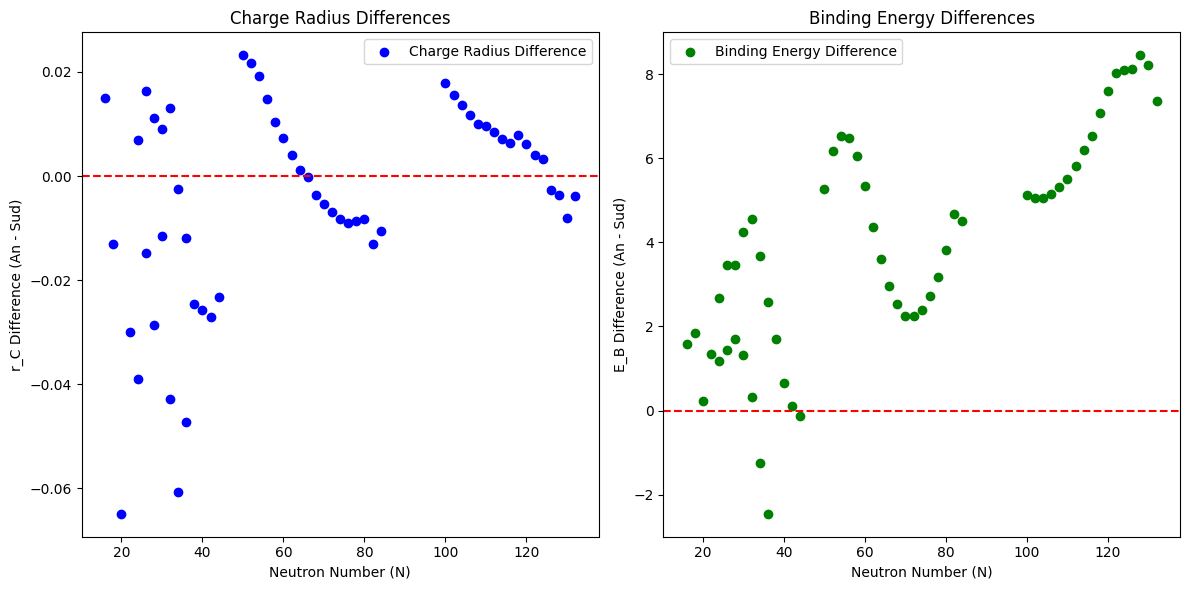

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(diff['N'], diff['r_C_diff'], color='blue', label='Charge Radius Difference')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Neutron Number (N)')
plt.ylabel('r_C Difference (An - Sud)')
plt.title('Charge Radius Differences')
plt.legend()
plt.subplot(1, 2, 2)
plt.scatter(diff['N'], diff['E_B_diff'], color='green', label='Binding Energy Difference')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Neutron Number (N)')
plt.ylabel('E_B Difference (An - Sud)')
plt.title('Binding Energy Differences')
plt.legend()
plt.tight_layout()
plt.show()